In [37]:
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

In [ ]:
vec1 = np.array([2, 2, 2, 3])
vec2 = np.array([3, 3, 3, 4])
print(vec1 @ vec2)
print(vec1.T @ vec2)
print(np.dot(vec1, vec2))
print(np.dot(vec1.T, vec2))

30
30
30
30


In [38]:
def linear_subproblem(c, a, b, l, u):
    n = len(c)
    x_star = []
    
    for i in range(n):
        if c[i] >= 0:
            x_star.append(l[i])
        else:
            x_star.append(u[i])
    
    if (a @ x_star) >= b:
        return x_star
    
    print("not in the corner")
    values = []
    coords = []
    # loop thru all the interesections (n???)
    for i in range(n):

        x = np.zeros(n)
        # xi = (b - ... ai-1*li-1 - ai+1*l1+1 - ... - an*ln) / a1
        x[i] = b
        for j in range(n):
            if i != j:
                if c[j] >= 0:
                    x[i] -= a[j]*l[j]
                    x[j] = l[j]
                else:
                    x[i] -= a[j]*u[j]
                    x[j] = u[j]
        x[i] /= a[i]

        # check if the point x is in the feasible region
        if (a @ x) >= b:
            coords.append(x)
            values.append(c @ x)
    
    
    # plot the intersection points 4D
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    x = [i[0] for i in coords]
    y = [i[1] for i in coords]
    z = [i[2] for i in coords]
    c = values

    img = ax.scatter(x, y, z, c=c, cmap=plt.hot())
    fig.colorbar(img)
    plt.show()
    # ????????

    min_idx = np.argmin(values)
    return coords[min_idx]
        

not in the corner


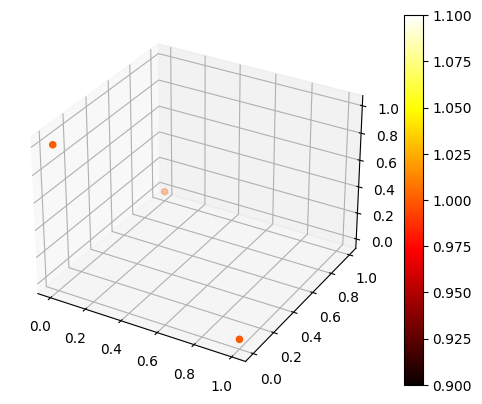

array([1., 0., 0.])

In [39]:
c = np.array([1, 1, 1])
a = np.array([1, 1, 1])
b = 1
l = np.array([0, 0, 0])
u = np.array([1, 1, 1])
solution = linear_subproblem(c, a, b, l, u)
solution

In [30]:
import numpy as np
from scipy.optimize import linprog

# Coefficients of the objective function
c = np.array([1, 1, 1])

# Coefficients matrix for inequality constraints (ax >= b)
A = -np.array([[1, 1, 1]])
b = -np.array([1])

# Bounds for the variables
x0_bounds = (0, 1)
x1_bounds = (0, 1)
x2_bounds = (0, 1)
bounds = [x0_bounds, x1_bounds, x2_bounds]

# Solving the linear problem
res = linprog(c, A_ub=A, b_ub=b, bounds=bounds, method='highs')

res.x, res.success, res.message

(array([0., 0., 1.]),
 True,
 'Optimization terminated successfully. (HiGHS Status 7: Optimal)')